# 07 因果方向與人生事件：是工作/家庭讓人快樂，還是快樂的人比較滿意？

橫斷面迴歸只能說「家庭滿意的人比較快樂」，但也可能反過來：天生樂觀的人對什麼都比較滿意（「由上而下」觀點，Diener, 1984）。
我們用追蹤資料做三種檢驗：

1. **個人固定效果模型（FE）**：只比較同一個人自己在不同年份的變化，排除「樂觀個性」這類不隨時間改變的特質（Ferrer-i-Carbonell & Frijters, 2004）。
2. **交叉延宕模型（cross-lagged panel）**：上一波的工作滿意度能不能預測下一波的幸福？上一波的幸福能不能預測下一波的工作滿意度？
   為了排除穩定的個人差異，另做「個人平均數中心化」版本，概念上接近 RI-CLPM（Hamaker, Kuiper & Grasman, 2015）。
   文獻參考：Bowling, Eschleman & Wang (2010) 的後設分析發現「生活滿意 → 工作滿意」的效果大於反方向。
3. **人生事件研究**：第一個孩子出生、失去工作，前後幾年的幸福變化（Clark et al., 2008；Myrskylä & Margolis, 2014）。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS
from psfd_utils import *
plt = setup_plot()
long = pd.read_csv(DERIVED / "long_2007_2024.csv", low_memory=False)
WAVES = sorted(long.year.unique())
widx = {y: i for i, y in enumerate(WAVES)}
long["wave_i"] = long.year.map(widx)

## 1. 固定效果 vs 一般迴歸（2007–2024 有工作者，兩題版幸福）

In [2]:
E = long[long.employed == 1].dropna(subset=["swb2", "jobsat", "famsat", "health", "age"]).copy()
cnt = E.groupby("pid").size(); E = E[E.pid.isin(cnt[cnt >= 2].index)]
# 用「全樣本」的標準差標準化（不在每波內標準化，才能看個人變化）
for c in ["swb2", "jobsat", "famsat", "health"]:
    E[c + "_s"] = (E[c] - E[c].mean()) / E[c].std()
P = E.set_index(["pid", "year"])
pooled = smf.ols("swb2_s ~ jobsat_s + famsat_s + health_s + age + I(age**2) + female + C(year)", E).fit(cov_type="cluster", cov_kwds={"groups": E.pid})
fe = PanelOLS.from_formula("swb2_s ~ jobsat_s + famsat_s + health_s + I(age**2) + TimeEffects + EntityEffects", P, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
cmp = pd.DataFrame({"一般迴歸（人與人比）": pooled.params[["jobsat_s", "famsat_s", "health_s"]],
                    "固定效果（同一人自己比）": fe.params[["jobsat_s", "famsat_s", "health_s"]]})
cmp.index = ["工作", "家庭", "健康"]
cmp["固定效果/一般迴歸"] = cmp.iloc[:, 1] / cmp.iloc[:, 0]
print("N =", len(E), "人數 =", E.pid.nunique())
cmp.round(3)

N = 41340 人數 = 6810


,一般迴歸（人與人比）,固定效果（同一人自己比）,固定效果/一般迴歸
工作,0.228,0.161,0.706
家庭,0.280,0.161,0.577
健康,0.236,0.150,0.633


In [3]:
print(fe.summary.tables[1])

                              Parameter Estimates                              
             Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-------------------------------------------------------------------------------
jobsat_s        0.1612     0.0063     25.396     0.0000      0.1488      0.1737
famsat_s        0.1615     0.0063     25.619     0.0000      0.1491      0.1738
health_s        0.1496     0.0064     23.550     0.0000      0.1372      0.1621
I(age ** 2)     0.0003  6.231e-05     4.5573     0.0000      0.0002      0.0004


固定效果的係數比一般迴歸小（工作剩約 70%、家庭剩約 58%），代表有一部分「滿意度 ↔ 幸福」的關聯來自穩定的個人特質（例如樂觀的人兩者都高）。
同一個人工作或家庭滿意度變好時，幸福仍明顯上升（兩者都約 +0.16 SD）。
**值得注意**：人與人之間比較時家庭明顯大於工作，但同一人自己比較時兩者一樣大。可能的解讀是：家庭滿意度的高低比較是長期、穩定的狀態（一個人家庭好不好，多半好多年），它對幸福的影響主要體現在「人與人之間的長期差距」；而短期的起伏，工作與家庭一樣重要。

## 2. 交叉延宕：誰預測誰？

In [4]:
E = E.sort_values(["pid", "year"])
g = E.groupby("pid")
for c in ["swb2_s", "jobsat_s", "famsat_s", "health_s"]:
    E[c + "_lag"] = g[c].shift(1)
E["gap"] = E.wave_i - g.wave_i.shift(1)
CL = E[E.gap == 1].dropna(subset=["swb2_s_lag", "jobsat_s_lag", "famsat_s_lag"]).copy()
print("相鄰兩波都有效的配對：", len(CL))
rows = []
for dv in ["swb2_s", "jobsat_s", "famsat_s"]:
    f = f"{dv} ~ swb2_s_lag + jobsat_s_lag + famsat_s_lag + health_s_lag + age + female + C(year)"
    m = smf.ols(f, CL).fit(cov_type="cluster", cov_kwds={"groups": CL.pid})
    for iv in ["swb2_s_lag", "jobsat_s_lag", "famsat_s_lag"]:
        rows.append(dict(版本="一般", 結果=dv, 前一波=iv, coef=m.params[iv], p=m.pvalues[iv]))
# 個人平均數中心化（移除穩定個人差異，近似 RI-CLPM）
CW = CL.copy()
for c in ["swb2_s", "jobsat_s", "famsat_s", "health_s", "swb2_s_lag", "jobsat_s_lag", "famsat_s_lag", "health_s_lag"]:
    CW[c] = CW[c] - CW.groupby("pid")[c].transform("mean")
CW = CW[CW.groupby("pid").pid.transform("size") >= 3]
for dv in ["swb2_s", "jobsat_s", "famsat_s"]:
    f = f"{dv} ~ swb2_s_lag + jobsat_s_lag + famsat_s_lag + health_s_lag + C(year)"
    m = smf.ols(f, CW).fit(cov_type="cluster", cov_kwds={"groups": CW.pid})
    for iv in ["swb2_s_lag", "jobsat_s_lag", "famsat_s_lag"]:
        rows.append(dict(版本="個人中心化", 結果=dv, 前一波=iv, coef=m.params[iv], p=m.pvalues[iv]))
cl = pd.DataFrame(rows)
nm = {"swb2_s": "幸福", "jobsat_s": "工作滿意", "famsat_s": "家庭滿意", "swb2_s_lag": "幸福", "jobsat_s_lag": "工作滿意", "famsat_s_lag": "家庭滿意"}
cl["結果"] = cl.結果.map(nm); cl["前一波"] = cl.前一波.map(nm)
cl.pivot_table(index=["版本", "前一波"], columns="結果", values="coef").round(3)

相鄰兩波都有效的配對： 32152


結果           家庭滿意   工作滿意     幸福
版本    前一波                      
一般    家庭滿意  0.309  0.052  0.100
      工作滿意  0.056  0.311  0.058
      幸福    0.150  0.106  0.425
個人中心化 家庭滿意 -0.046 -0.013  0.029
      工作滿意 -0.000 -0.031  0.022
      幸福    0.049  0.036  0.001

In [5]:
cl.pivot_table(index=["版本", "前一波"], columns="結果", values="p").round(4)

結果            家庭滿意    工作滿意      幸福
版本    前一波                         
一般    家庭滿意  0.0000  0.0000  0.0000
      工作滿意  0.0000  0.0000  0.0000
      幸福    0.0000  0.0000  0.0000
個人中心化 家庭滿意  0.0000  0.0649  0.0000
      工作滿意  0.9954  0.0001  0.0009
      幸福    0.0000  0.0000  0.9406

讀法（看「一般」版本，非對角線的格子）：
- 前一波**家庭滿意 → 下一波幸福** vs 前一波**幸福 → 下一波家庭滿意**，哪個大？
- 前一波**工作滿意 → 下一波幸福** vs 前一波**幸福 → 下一波工作滿意**，哪個大？

個人中心化版本中，自我延宕係數會因 Nickell 偏誤（短追蹤期）而偏負，重點看交叉項的方向與相對大小。

## 3. 人生事件：第一個孩子出生、失去工作

事件研究設計：以事件發生的那一波為 0，看前 2 波到後 3 波的幸福變化，控制個人固定效果與年份效果，以「事件前一波」為基準。

In [6]:
A = long.dropna(subset=["swb2"]).sort_values(["pid", "year"]).copy()
A["swb2_s"] = (A.swb2 - A.swb2.mean()) / A.swb2.std()
g = A.groupby("pid")


def event_study(df, flag_col, name, window=(-2, 3)):
    """flag_col：第一次發生事件的那一波 = 1"""
    first = df[df[flag_col] == 1].groupby("pid").wave_i.min()
    d = df[df.pid.isin(first.index)].copy()
    d["et"] = d.wave_i - d.pid.map(first)
    d = d[d.et.between(window[0] - 1, window[1] + 2)]
    d["et_c"] = d.et.clip(window[0], window[1])
    dummies = pd.get_dummies(d.et_c.astype(int), prefix="et").astype(float)
    base = f"et_-1"
    dummies = dummies.drop(columns=[base])
    dd = pd.concat([d[["pid", "year", "swb2_s"]], dummies], axis=1).set_index(["pid", "year"])
    cols = list(dummies.columns)
    m = PanelOLS(dd.swb2_s, dd[cols], entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)
    out = pd.DataFrame({"et": [int(c.split("_")[1]) for c in cols], "coef": m.params.values,
                        "lo": m.conf_int().iloc[:, 0].values, "hi": m.conf_int().iloc[:, 1].values})
    out = pd.concat([out, pd.DataFrame({"et": [-1], "coef": [0.0], "lo": [0.0], "hi": [0.0]})]).sort_values("et")
    out["事件"] = name; out["人數"] = d.pid.nunique()
    return out


# 第一個孩子出生：上一波沒有小孩、這一波有小孩，而且最小子女 ≤ 2 歲
A["nk_prev"] = g.nkids.shift(1)
A["first_child"] = ((A.nk_prev == 0) & (A.nkids == 1) & (A.youngest_child_age <= 2)).astype(int)
# 失去工作：上一波有工作、這一波沒有，且 60 歲以下（排除退休）
A["emp_prev"] = g.employed.shift(1)
A["job_loss"] = ((A.emp_prev == 1) & (A.employed == 0) & (A.age < 60)).astype(int)
ev1 = event_study(A, "first_child", "第一個孩子出生")
ev2 = event_study(A, "job_loss", "失去工作（60 歲以下）")
ev = pd.concat([ev1, ev2])
ev.round(3)

,et,coef,lo,hi,事件,人數
0,-2,-0.085,-0.155,-0.016,第一個孩子出生,1374
0,-1,0.000,0.000,0.000,第一個孩子出生,1374
1,0,0.002,-0.061,0.064,第一個孩子出生,1374
2,1,-0.156,-0.248,-0.063,第一個孩子出生,1374
3,2,-0.174,-0.301,-0.047,第一個孩子出生,1374
4,3,-0.177,-0.356,0.002,第一個孩子出生,1374
0,-2,0.068,-0.004,0.140,失去工作（60 歲以下）,1623
0,-1,0.000,0.000,0.000,失去工作（60 歲以下）,1623
1,0,-0.179,-0.247,-0.110,失去工作（60 歲以下）,1623
2,1,-0.053,-0.144,0.038,失去工作（60 歲以下）,1623


PosixPath('figures/fig07_events.png')

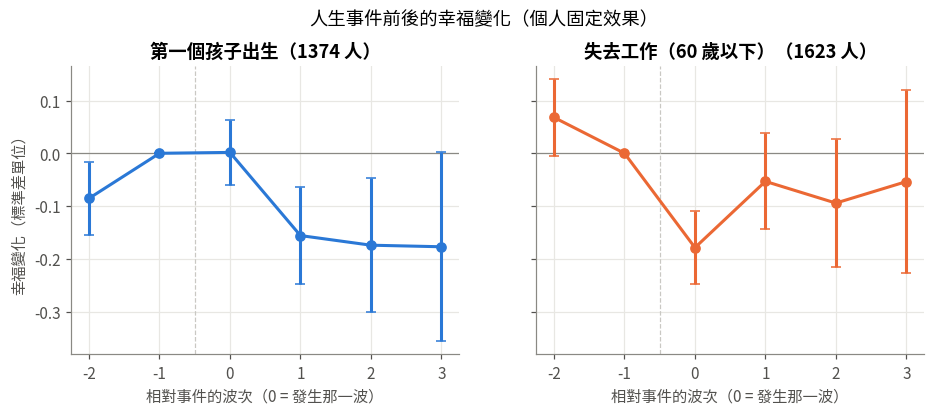

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (nm_, t), col in zip(axes, ev.groupby("事件", sort=False), [C_FAMILY, C_WORK]):
    ax.axhline(0, color="#8a8984", lw=0.8); ax.axvline(-0.5, color="#c9c8c3", lw=0.8, ls="--")
    ax.errorbar(t.et, t.coef, yerr=[t.coef - t.lo, t.hi - t.coef], marker="o", color=col, capsize=3)
    ax.set_title(f"{nm_}（{int(t.人數.iloc[0])} 人）"); ax.set_xlabel("相對事件的波次（0 = 發生那一波）")
    ax.set_xticks(range(-2, 4))
axes[0].set_ylabel("幸福變化（標準差單位）")
fig.suptitle("人生事件前後的幸福變化（個人固定效果）", y=1.03)
savefig(fig, "fig07_events")

## 4. 婚姻轉變（2016–2024，婚姻狀態有直接題的波次）

In [8]:
M = A[A.year >= 2016].copy()
gm = M.groupby("pid")
M["mar_prev"] = gm.married.shift(1)
M["got_married"] = ((M.mar_prev == 0) & (M.married == 1)).astype(int)
print("2016–2024 期間由未婚變已婚的人數：", M.groupby("pid").got_married.max().sum())
Mm = M[M.pid.isin(M[M.got_married == 1].pid)].copy()
Mm["after"] = Mm.groupby("pid").got_married.cummax()
Pm = Mm.set_index(["pid", "year"])
mmar = PanelOLS.from_formula("swb2_s ~ after + TimeEffects + EntityEffects", Pm).fit(cov_type="clustered", cluster_entity=True)
print("結婚後 vs 結婚前（同一人）的幸福差：", round(mmar.params["after"], 3), "SD，p =", round(mmar.pvalues["after"], 4))

2016–2024 期間由未婚變已婚的人數： 809
結婚後 vs 結婚前（同一人）的幸福差： 0.08 SD，p = 0.112


In [9]:
cmp.to_csv(DERIVED / "fe_vs_pooled.csv"); cl.to_csv(DERIVED / "cross_lagged.csv", index=False); ev.to_csv(DERIVED / "event_studies.csv", index=False)